In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis (EDA)

In this stage, we explore the Bankruptcy Prevention dataset to understand its structure and quality before building machine learning models. We inspect the column names, data types, missing values, duplicate records, and target-class distribution.

We also visualize the six input features and examine how their values relate to the bankruptcy and non-bankruptcy classes. These steps help us understand the data and identify patterns that we can investigate during model development.

In [3]:
# Load the semicolon-separated dataset
df = pd.read_csv("Bankruptcy_prevention_Dataset.csv", sep=";")

# Remove accidental spaces from column names and text values
df.columns = df.columns.str.strip()

for column in df.select_dtypes(include=["object"]).columns:
    df[column] = df[column].str.strip()

# Display the first few records
df.head()

C:\Users\balan\AppData\Local\Temp\ipykernel_30820\2919631252.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include=["object"]).columns:


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


### 1. Understanding the Dataset

First, we load the dataset and inspect sample records. We then review the column names, data types, summary statistics, and overall dataset dimensions.

The dataset contains six input features related to business risk and financial strength, plus a target column named `class`. The target identifies each record as `bankruptcy` or `non-bankruptcy`.

In [5]:
# Check column names, data types, and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    str    
dtypes: float64(6), str(1)
memory usage: 16.8 KB


In [6]:
# Review summary statistics for the numerical columns
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
# Check the total number of rows and columns
df.shape

(250, 7)

### 2. Checking Data Quality

We check for missing values, count duplicate rows, and inspect the number of unique values in each column. These checks help us understand the dataset before preprocessing.

Our initial inspection found 250 rows and 7 columns, no missing values, and 147 duplicate rows. We also check whether identical combinations of the six input features have conflicting target labels. This is important because repeated or conflicting profiles can affect model evaluation.

We remove duplicate rows later, following our mentor's instruction, and compare the dataset size before and after removal.

In [9]:
# Check for missing values in each column
df.isnull().sum()

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

In [10]:
# Count duplicate rows before deciding how to handle them
df.duplicated().sum()

np.int64(147)

In [11]:
# Check the number of unique values in each column
df.nunique()

industrial_risk          3
management_risk          3
financial_flexibility    3
credibility              3
competitiveness          3
operating_risk           3
class                    2
dtype: int64

In [12]:
# Inspect duplicate records to understand repeated patterns
df[df.duplicated()]

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
11,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
13,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
15,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
16,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
18,0.5,1.0,0.0,0.0,0.0,1.0,bankruptcy
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy


In [13]:
# Check whether identical feature combinations have different class labels
df_group=df.groupby(['industrial_risk','management_risk','financial_flexibility','credibility','competitiveness','operating_risk'])['class'].nunique()
df_group

industrial_risk  management_risk  financial_flexibility  credibility  competitiveness  operating_risk
0.0              0.0              0.0                    0.0          0.0              1.0               1
                                  0.5                    0.5          0.5              0.0               1
                                                                      1.0              0.0               1
                                                                                       1.0               1
                                                         1.0          0.5              0.0               1
                                                                                                        ..
1.0              1.0              1.0                    0.5          1.0              1.0               1
                                                         1.0          0.5              1.0               1
                                          

In [14]:
df_group.value_counts()

class
1    103
Name: count, dtype: int64

In [15]:
df.groupby('industrial_risk')['class'].value_counts(normalize=True)

industrial_risk  class         
0.0              non-bankruptcy    0.675000
                 bankruptcy        0.325000
0.5              non-bankruptcy    0.654321
                 bankruptcy        0.345679
1.0              bankruptcy        0.595506
                 non-bankruptcy    0.404494
Name: proportion, dtype: float64

In [16]:
df.groupby('management_risk')['class'].value_counts(normalize=True)

management_risk  class         
0.0              non-bankruptcy    0.822581
                 bankruptcy        0.177419
0.5              non-bankruptcy    0.666667
                 bankruptcy        0.333333
1.0              bankruptcy        0.613445
                 non-bankruptcy    0.386555
Name: proportion, dtype: float64

In [17]:
df.groupby('financial_flexibility')['class'].value_counts(normalize=True)

financial_flexibility  class         
0.0                    bankruptcy        0.857143
                       non-bankruptcy    0.142857
0.5                    non-bankruptcy    0.945946
                       bankruptcy        0.054054
1.0                    non-bankruptcy    0.982456
                       bankruptcy        0.017544
Name: proportion, dtype: float64

In [18]:
df.groupby('credibility')['class'].value_counts(normalize=True)

credibility  class         
0.0          bankruptcy        0.925532
             non-bankruptcy    0.074468
0.5          non-bankruptcy    0.779221
             bankruptcy        0.220779
1.0          non-bankruptcy    0.962025
             bankruptcy        0.037975
Name: proportion, dtype: float64

In [19]:
df.groupby('competitiveness')['class'].value_counts(normalize=True)

competitiveness  class         
0.0              bankruptcy        1.000000
0.5              non-bankruptcy    0.928571
                 bankruptcy        0.071429
1.0              non-bankruptcy    1.000000
Name: proportion, dtype: float64

In [20]:
df.groupby('operating_risk')['class'].value_counts(normalize=True)

operating_risk  class         
0.0             non-bankruptcy    0.759494
                bankruptcy        0.240506
0.5             non-bankruptcy    0.578947
                bankruptcy        0.421053
1.0             bankruptcy        0.561404
                non-bankruptcy    0.438596
Name: proportion, dtype: float64

### 3. Understanding the Target Class

Before building the models, we examine the distribution of the target variable, `class`. This tells us how many records belong to each category.

The original dataset contains 107 bankruptcy records (42.8%) and 143 non-bankruptcy records (57.2%). The classes are reasonably balanced, although their counts are not identical.

This information helps us choose evaluation metrics and avoid relying on accuracy alone.

In [22]:
df['class'].value_counts()

class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

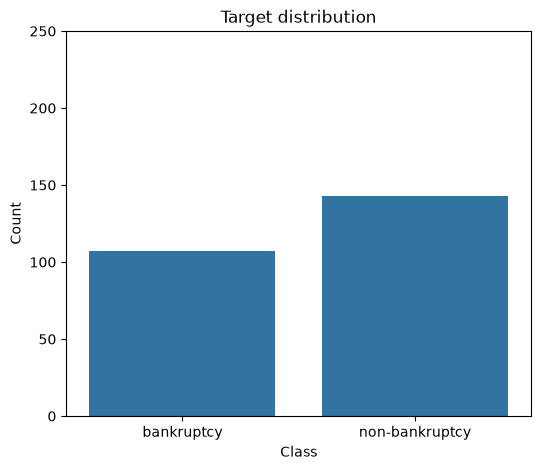

In [23]:
# Visualize the number of records in each target class
plt.figure(figsize=(6,5))
sns.countplot(data=df,x='class')
plt.title('Target distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.ylim(0,250)
plt.show()

### 4. Analyzing Feature Distributions

We use count plots to examine how frequently each input feature takes the values 0, 0.5, and 1.

These plots help us understand the distribution of the risk and financial-strength features. For example, we can compare how common each management-risk level is in the dataset.

Feature distributions describe the data; by themselves, they do not establish which feature is most important for predicting bankruptcy.

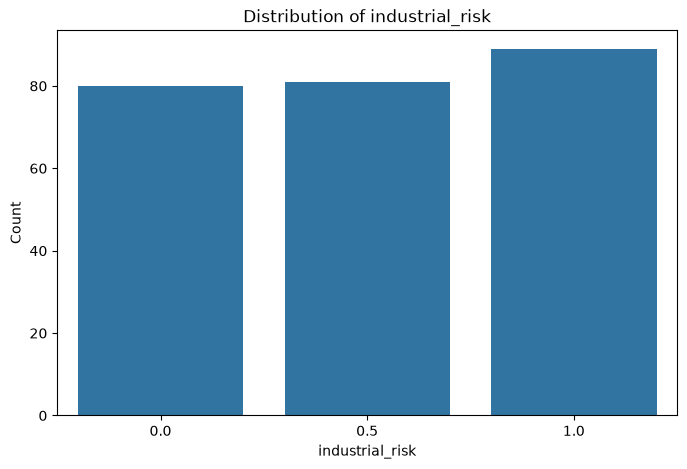

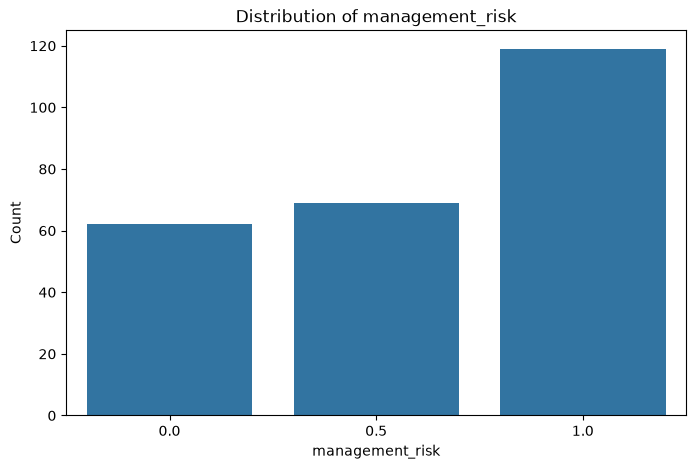

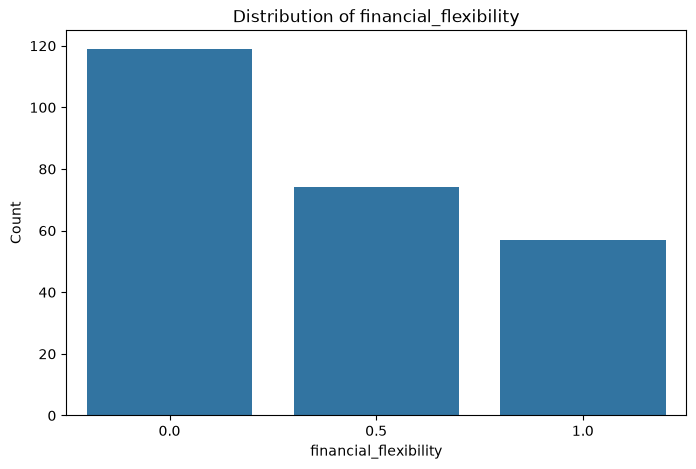

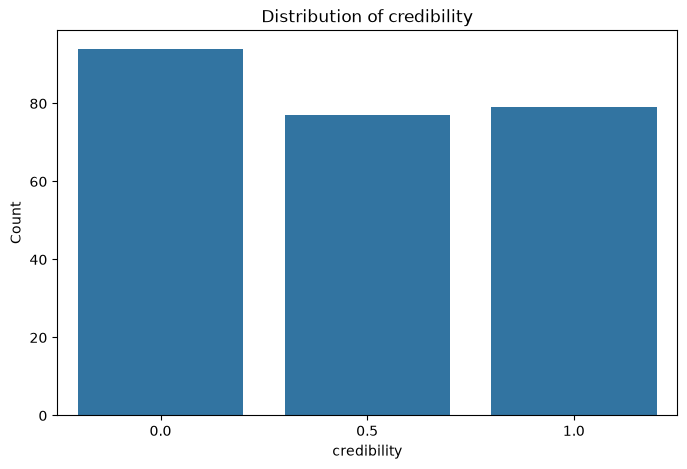

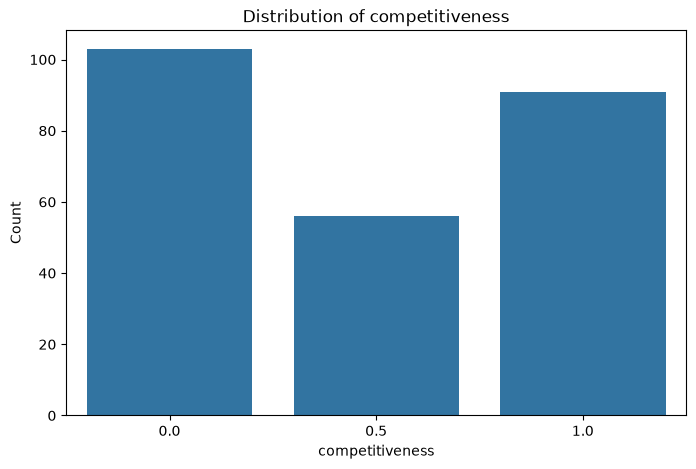

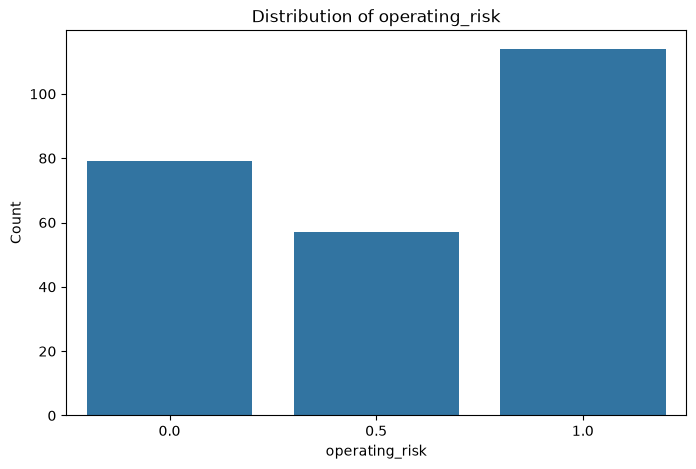

In [25]:
# Plot the distribution of each input feature to compare its value counts
columns = ['industrial_risk','management_risk','financial_flexibility','credibility','competitiveness','operating_risk']
for column in columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df,x=column)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.show()

### 5. Exploring Features Against the Target Class

We compare each input feature with the target class using count plots and the `hue` parameter. This allows us to see the counts of bankruptcy and non-bankruptcy records at each feature level.

The plots help us identify patterns in this dataset. For example, the earlier group analysis suggests that bankruptcy is more common at higher management-risk levels, while higher financial flexibility is associated with a lower bankruptcy proportion.

These are observed associations, not proof of causation. We use model evaluation to assess how well the features work together for classification.

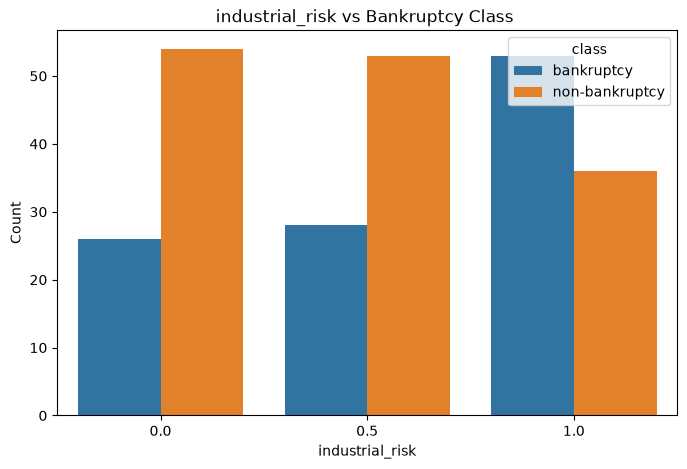

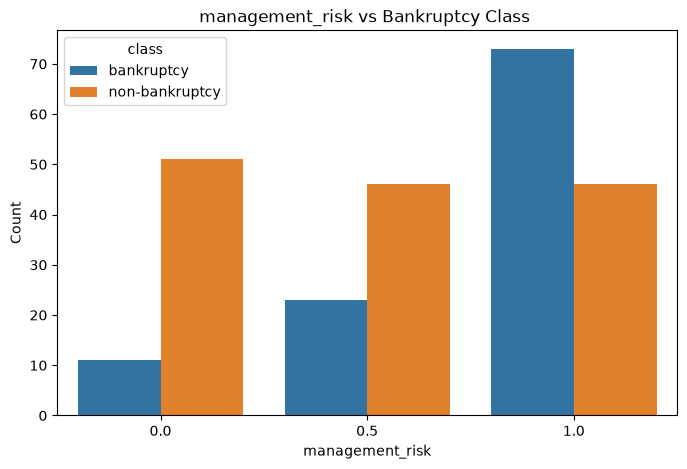

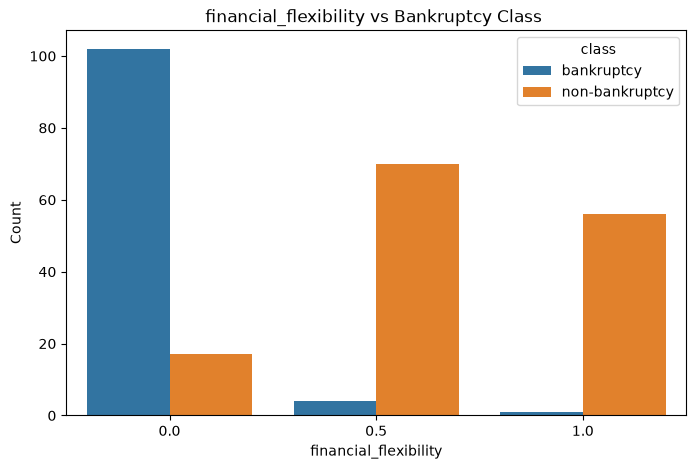

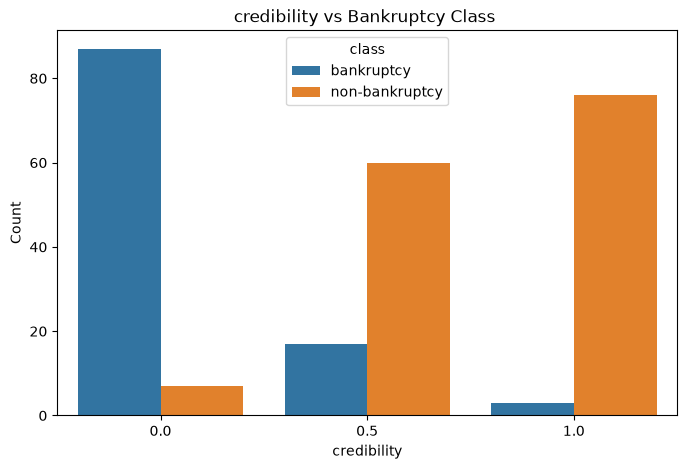

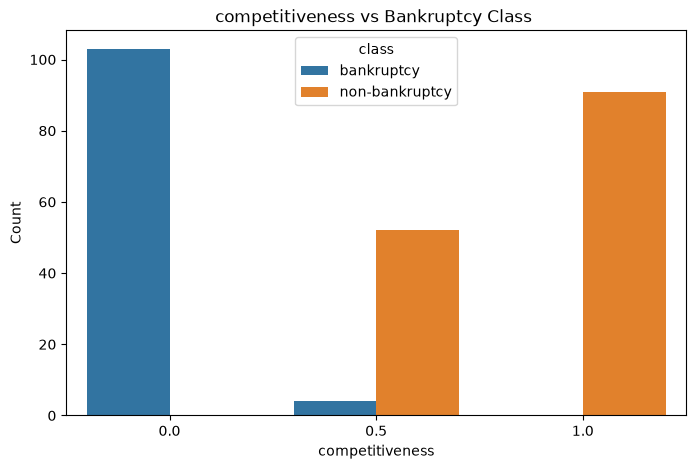

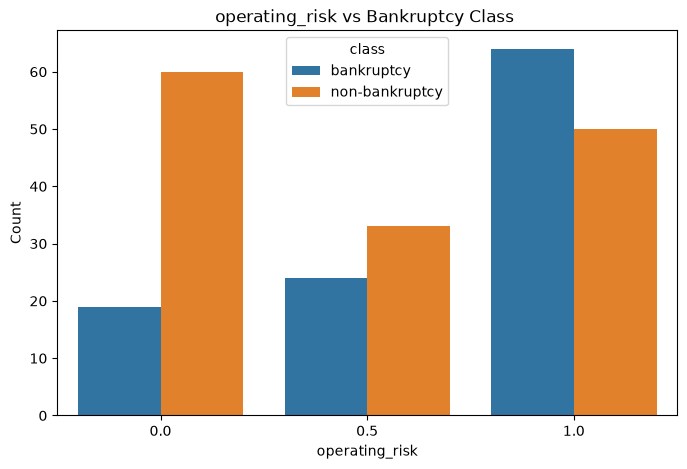

In [27]:
# Compare bankruptcy and non-bankruptcy counts across each feature level
for column in columns:
    plt.figure(figsize=(8, 5))
    sns.countplot(data=df,x=df[column],hue='class')
    plt.title(f'{column} vs Bankruptcy Class ')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.show()

### 6. Correlation Analysis

We use a correlation heatmap to examine relationships among the six numerical input features. Correlation values range from -1 to +1. Positive values indicate that two features tend to vary in the same direction, while negative values indicate that they tend to vary in opposite directions.

In our heatmap, financial flexibility and competitiveness have a positive correlation of approximately 0.69. Credibility and competitiveness also have a positive correlation of approximately 0.68.

These relationships suggest that some features may contain related information. Correlation does not establish causation. The heatmap uses the input features and does not directly show their relationship with the target class.

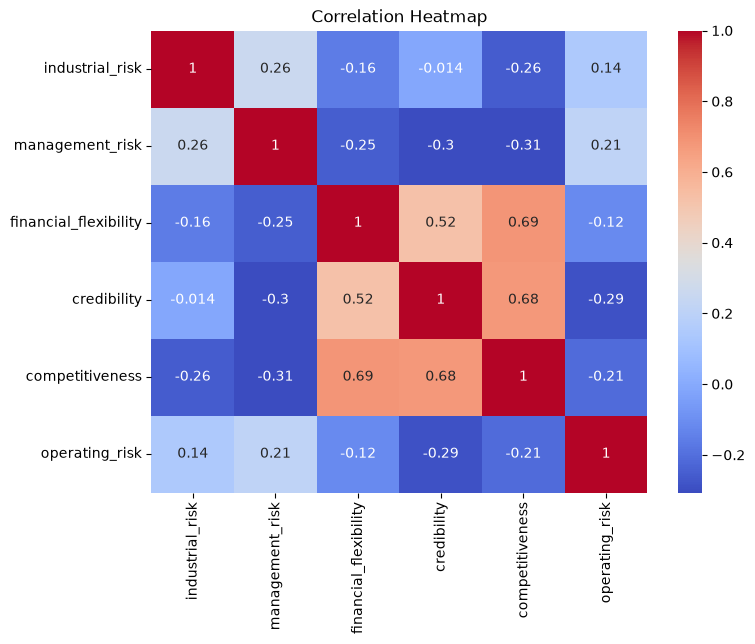

In [29]:
# Visualize correlations between the numerical input features
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### 7. Summary of Exploratory Data Analysis

Through EDA, we examined the dataset's structure, data quality, target distribution, feature distributions, and relationships among input variables.

The original dataset contains 250 records, six input features, and one target column. We found no missing values and identified 147 duplicate rows. The target distribution contains 107 bankruptcy records and 143 non-bankruptcy records.

The feature comparisons revealed associations between risk factors, financial strength, and the target class. The correlation heatmap also showed relationships between some input features.

### 8. Data Preprocessing

In this stage, we prepare the dataset for machine learning. Following our mentor's instruction, we remove duplicate rows and check the dataset dimensions and target distribution again.

We then separate the input features from the target column. The six input features describe business risks and financial conditions, while `class` contains the category that the models will learn to predict.

In [32]:
# Check the dataset size before removing duplicates
print("Shape before removing duplicates:", df.shape)

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Verify that duplicates have been removed
print("Shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

# Check the target distribution after removing duplicates
print("\nTarget distribution:")
print(df["class"].value_counts())

Shape before removing duplicates: (250, 7)
Shape after removing duplicates: (103, 7)
Remaining duplicates: 0

Target distribution:
class
non-bankruptcy    78
bankruptcy        25
Name: count, dtype: int64


### 9. Separating Input Features and Target

We separate the dataset into input features (`X`) and the target variable (`y`). The input features contain the six business-risk and financial-strength columns. The target variable is the `class` column, which the models will predict.

We check the resulting dimensions and feature names to confirm that the data has been separated correctly.

In [34]:
# Select the six input features
X = df.drop("class", axis=1)

# Select the target column
y = df["class"]

# Check the dimensions
print("Input features shape:", X.shape)
print("Target shape:", y.shape)

# Check the feature columns
print("\nInput feature columns:")
print(X.columns.tolist())

Input features shape: (103, 6)
Target shape: (103,)

Input feature columns:
['industrial_risk', 'management_risk', 'financial_flexibility', 'credibility', 'competitiveness', 'operating_risk']


### 10. Train-Test Split

We divide the deduplicated dataset into training and testing sets. The training set is used to fit the models, while the held-out testing set is used to evaluate their predictions on records not used during fitting.

We use an 80:20 split and `stratify=y` to preserve approximately the same class proportions in both sets. The `random_state=42` setting makes the split reproducible.

In [36]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the size of each set
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Check the class distribution in each set
print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

X_train: (82, 6)
X_test: (21, 6)
y_train: (82,)
y_test: (21,)

Training class distribution:
class
non-bankruptcy    62
bankruptcy        20
Name: count, dtype: int64

Testing class distribution:
class
non-bankruptcy    16
bankruptcy         5
Name: count, dtype: int64


### 11. Model Building

We train four classification algorithms: Logistic Regression, Decision Tree, Random Forest, and Support Vector Machine (SVM).

Logistic Regression and SVM are placed in pipelines with `StandardScaler`, because these algorithms can benefit from scaled input features. Decision Tree and Random Forest do not require feature scaling for this dataset.

All models use the same training split so that we can compare their performance fairly.

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create the models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} trained successfully.")

Logistic Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.
SVM trained successfully.


### 12. Model Evaluation

We evaluate each trained model on the held-out testing set using accuracy, bankruptcy precision, bankruptcy recall, and bankruptcy F1-score. We focus on bankruptcy recall because failing to identify a bankruptcy case may be costly in a prevention-oriented project.

We also print a classification report and confusion matrix for each model. These results show the types of correct and incorrect predictions made on the test set. Because the dataset is small, we also use five-fold cross-validation to obtain a more stable comparison across different splits.

In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

results = []

for name, model in models.items():

    # Predict the testing data
    y_pred = model.predict(X_test)

    # Calculate metrics specifically for bankruptcy
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Bankruptcy Precision": precision_score(
            y_test, y_pred,
            pos_label="bankruptcy",
            zero_division=0
        ),
        "Bankruptcy Recall": recall_score(
            y_test, y_pred,
            pos_label="bankruptcy",
            zero_division=0
        ),
        "Bankruptcy F1-score": f1_score(
            y_test, y_pred,
            pos_label="bankruptcy",
            zero_division=0
        )
    })

    print(f"\n{'=' * 45}")
    print(name)
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test,
        y_pred,
        labels=["bankruptcy", "non-bankruptcy"]
    ))

# Display all model results in one table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Bankruptcy Recall",
    ascending=False
).reset_index(drop=True)

results_df


Logistic Regression

Classification Report:
                precision    recall  f1-score   support

    bankruptcy       1.00      1.00      1.00         5
non-bankruptcy       1.00      1.00      1.00        16

      accuracy                           1.00        21
     macro avg       1.00      1.00      1.00        21
  weighted avg       1.00      1.00      1.00        21

Confusion Matrix:
[[ 5  0]
 [ 0 16]]

Decision Tree

Classification Report:
                precision    recall  f1-score   support

    bankruptcy       1.00      1.00      1.00         5
non-bankruptcy       1.00      1.00      1.00        16

      accuracy                           1.00        21
     macro avg       1.00      1.00      1.00        21
  weighted avg       1.00      1.00      1.00        21

Confusion Matrix:
[[ 5  0]
 [ 0 16]]

Random Forest

Classification Report:
                precision    recall  f1-score   support

    bankruptcy       1.00      1.00      1.00         5
non-bankrupt

,Model,Accuracy,Bankruptcy Precision,Bankruptcy Recall,Bankruptcy F1-score
0,Logistic Regression,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0
3,SVM,1.0,1.0,1.0,1.0


In [41]:
# Check whether any identical feature profiles occur in both sets.
# Because the full dataset was deduplicated before splitting, this helps
# verify that the same six-feature profile is not present in both sets.

train_profiles = set(map(tuple, X_train.to_numpy()))
test_profiles = set(map(tuple, X_test.to_numpy()))

overlapping_profiles = train_profiles.intersection(test_profiles)

print("Unique training profiles:", len(train_profiles))
print("Unique testing profiles:", len(test_profiles))
print("Overlapping profiles:", len(overlapping_profiles))

Unique training profiles: 82
Unique testing profiles: 21
Overlapping profiles: 0


In [42]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score, f1_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "bankruptcy_recall": make_scorer(
        recall_score,
        pos_label="bankruptcy",
        zero_division=0
    ),
    "bankruptcy_f1": make_scorer(
        f1_score,
        pos_label="bankruptcy",
        zero_division=0
    )
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores["test_accuracy"].mean(),
        "Mean Bankruptcy Recall": scores["test_bankruptcy_recall"].mean(),
        "Mean Bankruptcy F1": scores["test_bankruptcy_f1"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
print(cv_results_df.round(3))

                 Model  Mean CV Accuracy  Mean Bankruptcy Recall  \
0  Logistic Regression              0.98                    0.92   
1        Decision Tree              0.98                    0.96   
2        Random Forest              0.99                    0.96   
3                  SVM              0.98                    0.92   

   Mean Bankruptcy F1  
0               0.956  
1               0.960  
2               0.978  
3               0.956  


### 13. Model Selection

We compare the models using their held-out test metrics and five-fold cross-validation results. We consider bankruptcy recall, F1-score, and overall accuracy rather than selecting a model based on accuracy alone.

In our cross-validation results, Random Forest achieved the highest mean accuracy and F1-score while matching the Decision Tree's mean bankruptcy recall. We therefore select Random Forest as our current candidate model. Its performance still needs to be interpreted cautiously because the dataset is small and cross-validation results are estimates, not guarantees of real-world performance.

Selected model: Random Forest
Test accuracy: 1.0

Classification Report:
                precision    recall  f1-score   support

    bankruptcy       1.00      1.00      1.00         5
non-bankruptcy       1.00      1.00      1.00        16

      accuracy                           1.00        21
     macro avg       1.00      1.00      1.00        21
  weighted avg       1.00      1.00      1.00        21



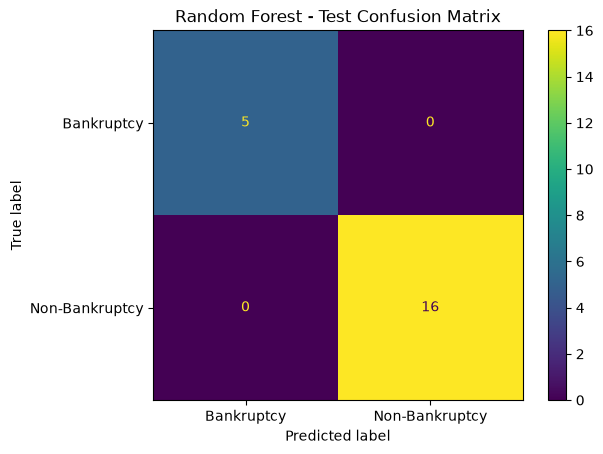

In [44]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)
import matplotlib.pyplot as plt

# Select Random Forest
best_model_name = "Random Forest"
best_model = models[best_model_name]

# Predict on the held-out test set
y_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)
print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["bankruptcy", "non-bankruptcy"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Bankruptcy", "Non-Bankruptcy"]
)

disp.plot()
plt.title("Random Forest - Test Confusion Matrix")
plt.show()


### 14. Testing a Sample Prediction

We test the selected model with one sample containing all six input features. This checks that the model accepts the expected feature names and returns a class label.

The sample prediction demonstrates how the trained model can be called for a new input. It is an example of model usage, not independent evidence of real-world predictive accuracy.

In [46]:
# Create one sample record using the six input features
import pandas as pd

sample_company = pd.DataFrame([{
    "industrial_risk": 0,
    "management_risk": 0,
    "financial_flexibility": 1,
    "credibility": 1,
    "competitiveness": 1,
    "operating_risk": 0
}])

prediction = best_model.predict(sample_company)[0]

print("Predicted class:", prediction)


Predicted class: non-bankruptcy


Feature Importance Ranking:
              Feature  Importance
      competitiveness    0.530524
financial_flexibility    0.211474
          credibility    0.145914
      industrial_risk    0.055419
       operating_risk    0.031122
      management_risk    0.025547


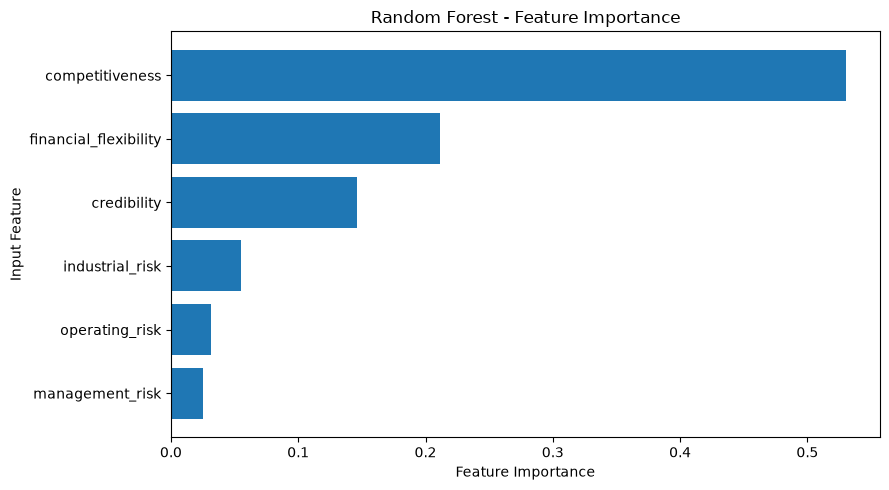

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

# Random Forest provides a built-in feature_importances_ attribute.
# These values describe the model's use of features; they do not prove causation.
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Feature Importance Ranking:")
print(importance_df.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Input Feature")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 15. Saving the Final Model

After selecting the Random Forest model, we save it to a `.pkl` file using `joblib`. This allows us to load the trained model in our Streamlit application without fitting it again.

The saved object is the trained model. For reliable loading, the Python, NumPy, scikit-learn, and joblib environments used to save and load it should be compatible.

In [49]:

import joblib

joblib.dump(
    best_model,
    "bankruptcy_prevention_model.pkl"
)

print("Final model saved successfully!")


Final model saved successfully!
